In [ ]:
# ═══════════════════════════════════════════════════════
# 0. INSTALLATION DES DÉPENDANCES
# ═══════════════════════════════════════════════════════
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
!pip install -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 771.9/771.9 kB 13.6 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.23.0
    Uninstalling huggingface_hub-1.23.0:
      Successfully uninstalled huggingface_hub-1.23.0


In [2]:
# ═══════════════════════════════════════════════════
# 1. IMPORTATIONS
# ═══════════════════════════════════════════════════
import pandas as pd
import re
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import classification_report
!pip install transformers torch pandas scikit-learn gradio matplotlib

In [ ]:
# ═══════════════════════════════════════════════════
# 2. CHARGEMENT DES DONNÉES
# ═══════════════════════════════════════════════════
from datasets import load_dataset

dataset = load_dataset(
    "Heliosoph/Jigsaw-Toxic-Comments",
    data_files="train.csv.gz",
    split="train"
)

df = dataset.to_pandas()

print("Dataset dimensions:", df.shape)
df.head()

README.md:   0%|          | 0.00/8.74k [00:00<?, ?B/s]

train.csv.gz:   0%|          | 0.00/26.7M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Dataset dimensions: (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [ ]:
# ═══════════════════════════════════════════════════
# 3. NETTOYAGE
# ═══════════════════════════════════════════════════
import re
def nettoyer(texte):
    texte = str(texte).lower()
    texte = re.sub(r"http\S+", "", texte)
    texte = re.sub(r"[^a-zA-Z0-9\s!?]", "", texte)
    return texte.strip()
df["texte_propre"] = df["comment_text"].apply(nettoyer)
df["label"]        = (df["toxic"] == 1).astype(int)
df = df[["texte_propre", "label"]].dropna()
print("Nettoyage terminé ✅")
print(df["label"].value_counts())

Nettoyage terminé ✅
label
0    144277
1     15294
Name: count, dtype: int64


In [ ]:
# ═══════════════════════════════════════════════════
# 4. TOKENISATION
# ═══════════════════════════════════════════════════
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokeniser(batch):
    return tokenizer(
        batch["texte_propre"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

print("Tokenizer chargé ✅")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer chargé ✅


In [ ]:
# ═══════════════════════════════════════════════════
# 5. CRÉATION ET DIVISION DU DATASET
# ═══════════════════════════════════════════════════
df_sample = df.sample(frac=0.5, random_state=42)

dataset = Dataset.from_pandas(df_sample)
dataset = dataset.map(tokeniser, batched=True)

split         = dataset.train_test_split(test_size=0.2, seed=42)
train_dataset = split["train"]   # 80% — le modèle apprend
test_dataset  = split["test"]    # 20% — évaluation finale

print(f"Train : {len(train_dataset)} exemples")
print(f"Test  : {len(test_dataset)} exemples")

Map:   0%|          | 0/79786 [00:00<?, ? examples/s]

Train : 63828 exemples
Test  : 15958 exemples


In [ ]:
# ═══════════════════════════════════════════════════
# 6. MODÈLE DistilBERT
# ═══════════════════════════════════════════════════
import os
from transformers import AutoModelForSequenceClassification
import torch
os.environ["HF_HUB_DISABLE_XET"] = "1"

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Modèle chargé avec succès sur :", device)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modèle chargé avec succès sur : cuda


In [ ]:
# ═══════════════════════════════════════════════════
# 7. ENTRAÎNEMENT
# ═══════════════════════════════════════════════════
training_args = TrainingArguments(
    output_dir                  = "./results",
    num_train_epochs            = 3,
    per_device_train_batch_size = 32,
    per_device_eval_batch_size  = 32,
    eval_strategy               = "no",
    save_strategy               = "epoch",
    load_best_model_at_end      = False,
    fp16                        = True,
)

trainer = Trainer(
    model         = model,
    args          = training_args,
    train_dataset = train_dataset
)

trainer.train()
print("Entraînement terminé ✅")
from google.colab import drive
drive.mount('/content/drive')
model.save_pretrained("/content/drive/MyDrive/toxicity_model")
tokenizer.save_pretrained("/content/drive/MyDrive/toxicity_model")
print("Modèle sauvegardé sur Drive ✅ — plus jamais besoin de réentraîner")

Step,Training Loss
500,0.133748
1000,0.110599
1500,0.107853
2000,0.099336
2500,0.059680
3000,0.063115
3500,0.057701
4000,0.061894
4500,0.023920
5000,0.027364


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Entraînement terminé ✅
Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé sur Drive ✅ — plus jamais besoin de réentraîner


F1-Score (toxique) : 81.2%
              precision    recall  f1-score   support

 Non toxique       0.98      0.98      0.98     14438
     Toxique       0.82      0.81      0.81      1520

    accuracy                           0.96     15958
   macro avg       0.90      0.89      0.90     15958
weighted avg       0.96      0.96      0.96     15958



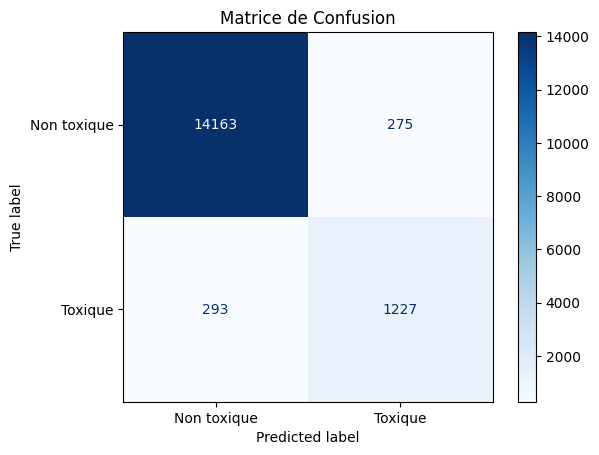

Toxiques bien détectés     : 1227
Toxiques ratés (dangereux) : 293
Fausses alarmes            : 275


In [ ]:
# ═══════════════════════════════════════════════════
# 8. ÉVALUATION DU MODÈLE
# ═══════════════════════════════════════════════════

from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
predictions = trainer.predict(test_dataset)
y_pred      = predictions.predictions.argmax(axis=1)
y_true      = predictions.label_ids
f1 = f1_score(y_true, y_pred, average="binary")
print(f"F1-Score (toxique) : {f1*100:.1f}%")

print(classification_report(
    y_true, y_pred,
    target_names=["Non toxique", "Toxique"]
))

cm   = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Non toxique","Toxique"])
disp.plot(cmap="Blues")
plt.title("Matrice de Confusion")
plt.show()

TP = cm[1][1]
FN = cm[1][0]
FP = cm[0][1]

print(f"Toxiques bien détectés     : {TP}")
print(f"Toxiques ratés (dangereux) : {FN}")
print(f"Fausses alarmes            : {FP}")

In [3]:
import pandas as pd
import re
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import classification_report
!pip install transformers torch pandas scikit-learn gradio matplotlib

# Recharger sans réentraîner
from google.colab import drive
drive.mount('/content/drive')

model     = AutoModelForSequenceClassification.from_pretrained("/content/drive/MyDrive/toxicity_model")
tokenizer = AutoTokenizer.from_pretrained("/content/drive/MyDrive/toxicity_model")
device    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model     = model.to(device)
print("Modèle rechargé ✅")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Modèle rechargé ✅


In [4]:
# ═══════════════════════════════════════════════════
# 9. Prediction
# ═══════════════════════════════════════════════════

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

def nettoyer(texte):
    texte = str(texte).lower()
    texte = re.sub(r"http\S+", "", texte)
    texte = re.sub(r"[^a-zA-Z0-9\s!?]", "", texte)
    return texte.strip()

def predire(texte):
    tokens = tokenizer(
        nettoyer(texte),
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        proba_toxique = model(**tokens).logits.softmax(dim=1)[0][1].item()

    if proba_toxique >= 0.5:
        label = "🔴 Toxique"
        confiance = proba_toxique
    else:
        label = "🟢 Non toxique"
        confiance = 1 - proba_toxique

    return f"{label} — confiance : {confiance*100:.0f}%"

In [5]:
# ═══════════════════════════════════════════════════
# 10. DÉMO GRADIO
# ═══════════════════════════════════════════════════
import gradio as gr

interface = gr.Interface(
    fn          = predire,
    inputs      = gr.Textbox(placeholder="Entrez un commentaire..."),
    outputs     = "text",
    title       = "🔍 Détecteur de Toxicité",
    description = "Analyse si un commentaire est toxique ou non."
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://64d7ba4ee3065c43ec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
